# 01 – Data och första titt på volatilitet

**Mål:** hämta kursdata för några svenska aktier, räkna ut avkastning och volatilitet, och se *varför* volatilitet går att förutsäga.

In [1]:
import sys
sys.path.append("..")  # så att vi hittar src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from src.data import load_prices, log_returns, realized_vol, future_vol

plt.rcParams["figure.figsize"] = (11, 4)

## 1. Hämta kurser
Första gången laddas datan ner från Yahoo Finance och sparas i `data/prices.csv`. Därefter läses den från fil.

In [2]:
prices = load_prices()
print(prices.shape)
prices.tail()

(4247, 6)


Ticker,Atlas Copco A,Ericsson B,H&M B,SEB A,Volvo B,OMXS30
Date,,,,,,
2026-11-18,188.750000,104.800003,178.899994,215.699997,318.000000,3256.209961
2026-11-19,190.250000,105.000000,178.350006,216.199997,320.200012,3256.719971
2026-11-20,181.949997,101.699997,178.100006,211.300003,313.700012,3175.060059
2026-11-23,190.899994,104.699997,182.199997,214.699997,321.000000,3261.320068
2026-11-24,185.399994,103.800003,181.500000,213.899994,313.100006,3223.650635


In [3]:
# Saknade värden per aktie (t.ex. om en aktie börjar senare)
prices.isna().sum()

Ticker
Atlas Copco A    0
Ericsson B       0
H&M B            0
SEB A            0
Volvo B          0
OMXS30           6
dtype: int64

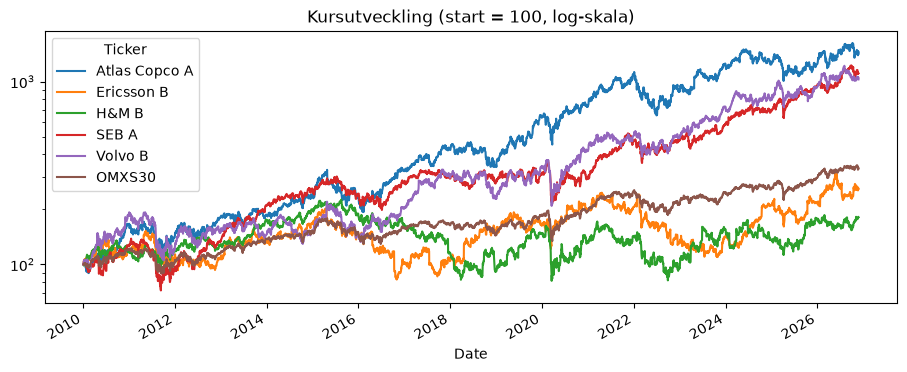

In [4]:
# Normalisera till 100 vid start så att aktierna går att jämföra
(prices / prices.bfill().iloc[0] * 100).plot(logy=True, title="Kursutveckling (start = 100, log-skala)")
plt.show()

## 2. Från kurs till avkastning
Vi jobbar med **log-avkastning** `r_t = ln(P_t / P_{t-1})`. Fördelen är att de går att summera över tid: veckans avkastning = summan av dagarnas.

In [5]:
rets = log_returns(prices)
rets.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
Ticker,,,,
Atlas Copco A,0.000625,0.018027,-0.104271,0.135036
Ericsson B,0.000224,0.019406,-0.225774,0.165710
H&M B,0.000140,0.018720,-0.139038,0.167025
SEB A,0.000567,0.016370,-0.149565,0.118605
Volvo B,0.000549,0.017930,-0.157025,0.139934
OMXS30,0.000279,0.011559,-0.111726,0.068491


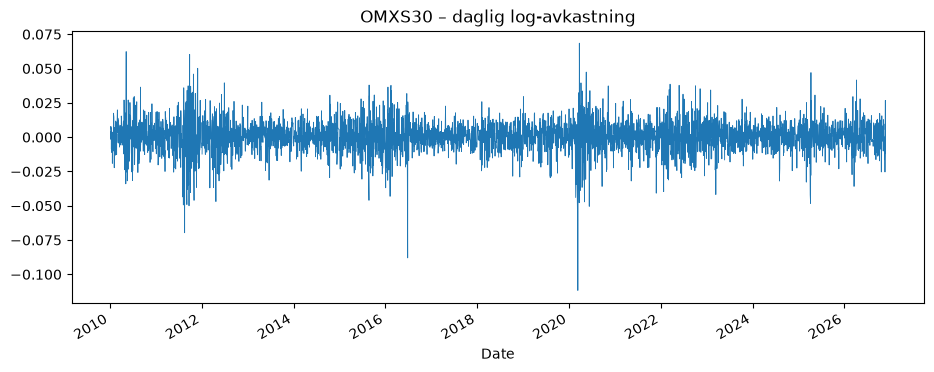

In [6]:
rets["OMXS30"].plot(title="OMXS30 – daglig log-avkastning", lw=0.6)
plt.show()

Titta på grafen: de stora utslagen ligger **samlade i perioder**. Det är det som kallas *volatility clustering*.

## 3. Volatilitet
Realiserad volatilitet = hur mycket avkastningen har svängt de senaste 21 dagarna (≈ en månad), uppräknat till årsbasis.
30 % betyder ungefär att aktien "normalt" kan röra sig ±30 % på ett år.

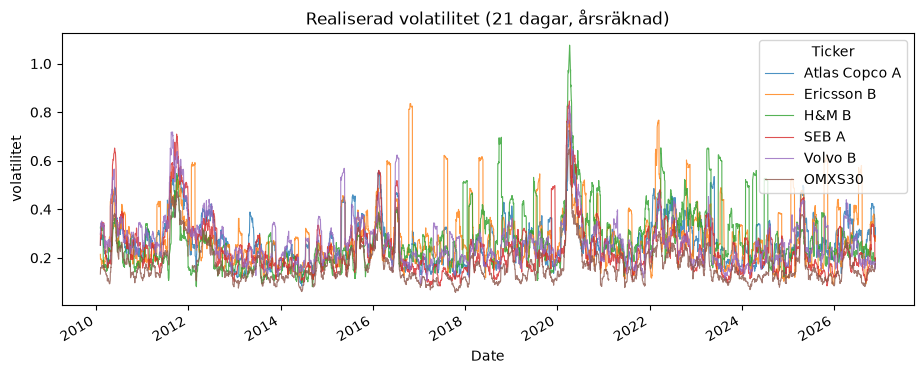

In [7]:
vol = realized_vol(rets, window=21)
vol.plot(title="Realiserad volatilitet (21 dagar, årsräknad)", lw=0.8, alpha=0.8)
plt.ylabel("volatilitet")
plt.show()

In [8]:
# Snittvolatilitet per aktie
vol.mean().sort_values()

Ticker
OMXS30           0.167674
SEB A            0.236072
Volvo B          0.265369
Atlas Copco A    0.269476
H&M B            0.271168
Ericsson B       0.283207
dtype: float64

## 4. Varför går volatilitet att förutsäga?
Vi mäter **autokorrelation**: hur mycket dagens värde liknar värdet för *k* dagar sedan.

- För avkastningen `r` borde den vara ≈ 0 (annars kunde man förutsäga kursen och bli rik).
- För storleken på rörelsen `|r|` förväntar vi oss positiv korrelation långt bak i tiden — det är klustringen.

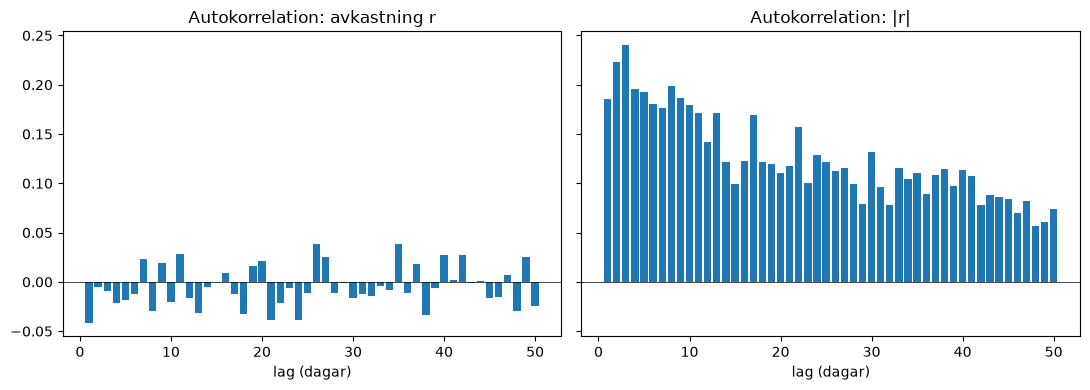

In [9]:
def autocorr(series, max_lag=50):
    s = series.dropna()
    return pd.Series([s.autocorr(lag) for lag in range(1, max_lag + 1)], index=range(1, max_lag + 1))

r = rets["OMXS30"]
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, s, title in [(axes[0], r, "avkastning r"), (axes[1], r.abs(), "|r|")]:
    ac = autocorr(s)
    ax.bar(ac.index, ac.values, width=0.8)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"Autokorrelation: {title}")
    ax.set_xlabel("lag (dagar)")
plt.tight_layout()
Path("../docs/images").mkdir(parents=True, exist_ok=True)
plt.savefig("../docs/images/volatility_clustering.png", dpi=150)  # används i README
plt.show()

## 5. Målvariabeln
Det vi ska förutsäga: **volatiliteten de kommande 5 dagarna** (`future_vol`).

Enklaste möjliga prognos: "framtiden blir som den senaste månaden". Hur mycket hänger de ihop?

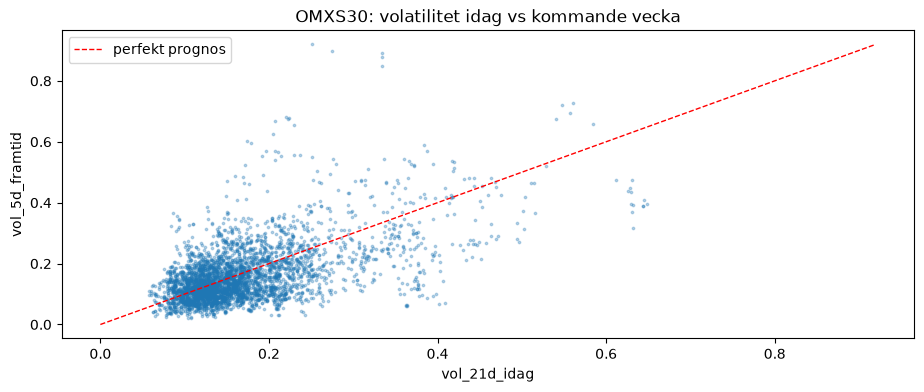

Korrelation: 0.56


In [10]:
target = future_vol(rets, horizon=5)

name = "OMXS30"
df = pd.DataFrame({"vol_21d_idag": vol[name], "vol_5d_framtid": target[name]}).dropna()

df.plot.scatter(x="vol_21d_idag", y="vol_5d_framtid", s=3, alpha=0.3,
                title=f"{name}: volatilitet idag vs kommande vecka")
lim = df.max().max()
plt.plot([0, lim], [0, lim], "r--", lw=1, label="perfekt prognos")
plt.legend()
plt.show()

print("Korrelation:", round(df.corr().iloc[0, 1], 2))

## Sammanfattning och nästa steg
- Avkastningen själv är nästan oförutsägbar, men **storleken** på rörelserna hänger ihop över tid.
- Redan "samma som förra månaden" ger en tydlig korrelation med framtida volatilitet. Det är vår första **baslinje**.

**Steg 2:** bygga baslinjerna ordentligt (naiv, EWMA, GARCH) och sätta upp walk-forward-utvärdering, så att vi har något att slå med ML.